# 02 Procesamiento de texto, recuperación secuencial e indexación

## Objetivo

Implementar y comparar dos mecanismos de recuperación de información —búsqueda secuencial e índice invertido— sobre colecciones de libros del Proyecto Gutenberg, investigando experimentalmente su rendimiento y escalabilidad.

### Parte A. Corpus pequeño

**1. Preparación del corpus**

Utilice los 18 documentos de la colección Gutenberg disponible en NLTK.

1. Cargue los textos originales.
2. Identifique el número de documentos y sus tamaños.
3. Implemente tokenización y normalización: conversión a minúsculas, tratamiento de puntuación y caracteres especiales.

Seleccione y documente una configuración de preprocesamiento que se utilizará consistentemente en todos los experimentos.



---

> **Resultados guardados.** Las partes A, B y C usan datos reales. Las tablas y graficas se pueden ver sin ejecutar el codigo. La configuracion esta en el ejercicio 1 y la descarga automatica del corpus grande esta desactivada.


In [1]:
# EJERCICIO 1. Se prepara el corpus de NLTK.
import os
import re
import time
import sys
import gc
import zipfile
import tarfile
import requests
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import gutenberg
from IPython.display import display

# Se configuran las rutas y los limites de recursos.
import hashlib
import json
import platform
import unicodedata
from datetime import datetime, timezone, timedelta
from pathlib import PurePosixPath
from IPython.display import Markdown
from IPython import get_ipython
if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")
from importlib.metadata import version
import psutil

BASE = Path.cwd()
DIRECTORIO_NLTK = Path(os.getenv("RI_NLTK_DATA", str(BASE / "nltk_data")))
if not DIRECTORIO_NLTK.exists() and (BASE.parent / "nltk_data").exists():
    DIRECTORIO_NLTK = BASE.parent / "nltk_data"
nltk.data.path.insert(0, str(DIRECTORIO_NLTK))
REPETICIONES = 30
URL_ARCHIVO = "https://www.gutenberg.org/cache/epub/feeds/txt-files.tar.zip"
# El corpus se guarda fuera de OneDrive. RI_ARCHIVO permite cambiar la ruta.
DIRECTORIO_TRABAJO = Path(os.getenv("LOCALAPPDATA", str(Path.home() / ".local"))) / "GutenbergRI"
RUTA_ARCHIVO = Path(os.getenv("RI_ARCHIVO", str(DIRECTORIO_TRABAJO / "txt-files.tar.zip")))
RUTA_TXT_EXTRAIDOS = Path(os.getenv("RI_TXT", str(DIRECTORIO_TRABAJO / "txt_extraidos")))
DESCARGAR_ARCHIVO_GRANDE = False  # Se activa solo si se autoriza la descarga.
MAX_DOCUMENTOS = 2000
TAMANOS_RECUPERACION = [100, 250, 500, 1000, 2000]
TAMANOS_OBJETIVO = [50, 100, 250, 500, 1000, 2000]
CONSULTA_ESCALABILIDAD = "xyzterminoinexistente987654321"
MAX_BYTES_TXT = 128 * 1024**2      # Se lee un TXT por vez, hasta 128 MiB.
MAX_TOKENS_B = 250_000_000         # Se limita la cantidad de tokens sin cortar libros.
MAX_RSS_MIB = 6144               # Se limita la memoria del proceso.
ESCANEAR_TODO = True             # Se recorre todo el archivo y se guardan 2000 documentos en RAM.
DIRECTORIO_RESULTADOS = BASE / "resultados_deber2"
pd.set_option("display.max_colwidth", 85)
pd.set_option("display.max_rows", 25)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})
print("Entorno:", platform.python_version(), platform.platform())
print("Ejecución (Ecuador):", datetime.now(timezone(timedelta(hours=-5))).isoformat(timespec="seconds"))
display(pd.DataFrame({"Paquete": ["nltk", "numpy", "pandas", "matplotlib", "requests", "psutil"],
                      "Versión": [version(p) for p in ["nltk", "numpy", "pandas", "matplotlib", "requests", "psutil"]]}))

# Se aplica la misma regla a documentos y consultas:
# Se usa casefold() y se separa por puntuacion,
# guiones y espacios. Se conservan letras y numeros Unicode.
# Se conservan stopwords y no se aplica stemming ni lematizacion.
# Esta regla no distingue C++ de C.
PATRON_TOKEN = re.compile(r"[^\W_]+", flags=re.UNICODE)

def tokenizar(texto):
    return PATRON_TOKEN.findall(texto.casefold())

# Se comprueba la tokenizacion con ejemplos conocidos.
assert tokenizar("Tutorías, TUTORÍAS; año 2026.") == ["tutorías", "tutorías", "año", "2026"]
assert tokenizar("No requiere experiencia") == ["no", "requiere", "experiencia"]

# RI_OFFLINE=1 impide la descarga de NLTK.
DESCARGAR_NLTK_SI_FALTA = os.getenv("RI_OFFLINE", "0") != "1"
try:
    ids_nltk = sorted(gutenberg.fileids())
except LookupError:
    ids_nltk = []
    if DESCARGAR_NLTK_SI_FALTA:
        try:
            print("Descargando el corpus pequeño NLTK Gutenberg...")
            if nltk.download("gutenberg", download_dir=str(DIRECTORIO_NLTK), quiet=True, raise_on_error=True):
                ids_nltk = sorted(gutenberg.fileids())
        except Exception as exc:
            print("No fue posible descargar NLTK Gutenberg:", str(exc)[:220])

textos_originales_A = {}
corpus_A = {}  # Se conserva el orden y las repeticiones de tokens.
resumen_A = []
for doc_id in ids_nltk:
    texto = gutenberg.raw(doc_id)
    tokens = tokenizar(texto)
    textos_originales_A[doc_id] = texto
    corpus_A[doc_id] = tokens
    resumen_A.append({"Documento": doc_id,
                      "Caracteres": len(texto),
                      "Bytes_UTF8": len(texto.encode("utf-8")),
                      "Tokens": len(tokens),
                      "Terminos_distintos": len(set(tokens))})

if ids_nltk and len(ids_nltk) != 18:
    raise RuntimeError("La colección NLTK debe contener exactamente 18 documentos.")

df_corpus_A = pd.DataFrame(resumen_A)
print("Documentos originales NLTK Gutenberg:", len(corpus_A))
print("Política: casefold + letras/números Unicode + puntuación como separador, sin stopwords ni stemming.")
if len(corpus_A) != 18:
    print("AVISO: para el ejercicio 1 se requieren 18 documentos; instale nltk_data/gutenberg y vuelva a ejecutar.")
if not df_corpus_A.empty:
    display(df_corpus_A)
    print("Total tokens:", f"{df_corpus_A['Tokens'].sum():,}")
    print("Vocabulario |V|:", len(set(t for tokens in corpus_A.values() for t in tokens)))

if corpus_A:
    display(Markdown(f"**Resultado del ejercicio 1.** Se cargaron **{len(corpus_A)} libros reales**, "
                     f"con **{df_corpus_A.Tokens.sum():,} tokens** y "
                     f"**{len(set(t for ts in corpus_A.values() for t in ts)):,} terminos**. "
                     "Los tokens cuentan apariciones y el vocabulario cuenta terminos distintos."))
else:
    display(Markdown("**Ejercicio 1 pendiente:** falta el corpus NLTK; las pruebas pequeñas no lo sustituyen."))


Entorno: 3.12.14 Windows-11-10.0.26300-SP0
Ejecución (Ecuador): 2026-10-26T20:48:55-05:00


,Paquete,Versión
0,nltk,3.10.4
1,numpy,2.3.5
2,pandas,3.0.1
3,matplotlib,3.11.2
4,requests,2.34.2
5,psutil,7.2.2


Documentos originales NLTK Gutenberg: 18
Política: casefold + letras/números Unicode + puntuación como separador, sin stopwords ni stemming.


,Documento,Caracteres,Bytes_UTF8,Tokens,Terminos_distintos
0,austen-emma.txt,887071,887071,161980,7103
1,austen-persuasion.txt,466292,466292,84167,5777
2,austen-sense.txt,673022,673022,120787,6336
3,bible-kjv.txt,4332554,4332554,854046,12744
4,blake-poems.txt,38153,38153,6936,1512
5,bryant-stories.txt,249439,249439,46699,3836
6,burgess-busterbrown.txt,84663,84663,16359,1527
7,carroll-alice.txt,144395,144395,27336,2570
8,chesterton-ball.txt,457450,457455,82865,8234
9,chesterton-brown.txt,406629,406629,73288,7739


Total tokens: 2,199,207
Vocabulario |V|: 41840


**Resultado del ejercicio 1.** Se cargaron **18 libros reales**, con **2,199,207 tokens** y **41,840 terminos**. Los tokens cuentan apariciones y el vocabulario cuenta terminos distintos.

**Preprocesamiento.** Se usa `casefold()` para convertir a minusculas. La puntuacion separa los tokens y se conservan letras, numeros Unicode y tildes. No se eliminan stopwords ni se aplica stemming. Por ejemplo, `C++` queda como `c` y `3,14` se divide en dos tokens.

Se buscan los TXT completos, incluidos sus encabezados. `Bytes_UTF8` mide el texto recodificado, no el archivo original. La regla conserva la diferencia entre caracteres Unicode compuestos y descompuestos.

**2. Búsqueda secuencial**

Implemente una función que reciba un término de consulta y devuelva los identificadores de todos los documentos que lo contienen con una búsqueda secuencial.

La implementación deberá utilizar obligatoriamente dos lazos `for` anidados: el primero recorre los documentos y el segundo los tokens de cada documento.

No es necesario utilizar índices invertidos, motores de búsqueda ni estructuras auxiliares que almacenen anticipadamente los documentos asociados a cada término.

Ejecute consultas con términos frecuentes, poco frecuentes e inexistentes.

In [2]:
# EJERCICIO 2. Se busca con dos for anidados.
def normalizar_termino(termino):
    partes = tokenizar(termino)
    if len(partes) != 1:
        raise ValueError("Se requiere exactamente UN término (no una frase vacía o de varias palabras).")
    return partes[0]

def buscar_secuencial(documentos, termino, *, normalizado=False):
    # La consulta se prepara antes de medir.
    if not normalizado:
        termino = normalizar_termino(termino)
    encontrados = []
    for doc_id, tokens in documentos.items():       # Se recorren los documentos.
        for token in tokens:                         # Se recorren los tokens del documento.
            if token == termino:
                encontrados.append(doc_id)
                break                               # Se evita repetir el documento en la salida.
    return sorted(encontrados)

# Se usa el ejemplo de clase para comprobar las respuestas.
corpus_prueba = {
    "D1": tokenizar("Las tutorías apoyan a estudiantes de primer año."),
    "D2": tokenizar("Un estudiante abandona la universidad por dificultades económicas."),
    "D3": tokenizar("La universidad evalúa tutorías para mejorar la permanencia."),
    "D4": tokenizar("El estudio analiza el abandono de mascotas.")
}
assert buscar_secuencial(corpus_prueba, "tutorías") == ["D1", "D3"]
assert buscar_secuencial(corpus_prueba, "ESTUDIANTES") == ["D1"]
assert buscar_secuencial(corpus_prueba, "palabrainexistente987") == []
print("Pruebas de búsqueda secuencial sobre los 4 documentos de clase: CORRECTAS")

def elegir_terminos(documentos):
    # Se usa DF para elegir las consultas, sin acelerar la busqueda.
    frecuencia_documental = Counter(
        termino for tokens in documentos.values() for termino in set(tokens))
    if not frecuencia_documental:
        return {"frecuente": "tutorías", "raro": "permanencia", "inexistente": "inexistente987654321"}
    frecuente = min(frecuencia_documental, key=lambda t: (-frecuencia_documental[t], len(t), t))
    candidatos = sorted(t for t, df in frecuencia_documental.items()
                        if df == 1 and 5 <= len(t) <= 12 and t.isalpha())
    raro = candidatos[0] if candidatos else min(frecuencia_documental, key=lambda t: (frecuencia_documental[t], t))
    inexistente = "xyzterminoinexistente987654321"
    while inexistente in frecuencia_documental:
        inexistente += "x"
    return {"frecuente": frecuente, "raro": raro, "inexistente": inexistente}

consultas_A = elegir_terminos(corpus_A) if corpus_A else None
resultados_A = pd.DataFrame()
if corpus_A:
    resultados_A = pd.DataFrame([
        {"Clase": tipo, "Término": palabra, "DF": len(ids), "Documentos recuperados": ids}
        for tipo, palabra in consultas_A.items()
        for ids in [buscar_secuencial(corpus_A, palabra)]])
    display(resultados_A)
    display(Markdown("**Resultado del ejercicio 2.** " + "; ".join(
        f"`{r['Término']}` ({r['Clase']}) aparece en **{r['DF']} {'documento' if r['DF'] == 1 else 'documentos'}**"
        for r in resultados_A.to_dict("records")) +
        ". La DF indica en cuantos documentos aparece cada termino. "
        "La busqueda recorre los tokens con los dos `for`."))
else:
    print("Ejercicio 2 con NLTK pendiente; solo se ejecutaron pruebas unitarias de clase.")


Pruebas de búsqueda secuencial sobre los 4 documentos de clase: CORRECTAS


,Clase,Término,DF,Documentos recuperados
0,frecuente,a,18,"[austen-emma.txt, austen-persuasion.txt, austen-sense.txt, bible-kjv.txt, blake-p..."
1,raro,aaronites,1,[bible-kjv.txt]
2,inexistente,xyzterminoinexistente987654321,0,[]


**Resultado del ejercicio 2.** `a` (frecuente) aparece en **18 documentos**; `aaronites` (raro) aparece en **1 documento**; `xyzterminoinexistente987654321` (inexistente) aparece en **0 documentos**. La DF indica en cuantos documentos aparece cada termino. Ese contador solo selecciona las consultas: la busqueda recorre los tokens con los dos `for`.

**Busqueda secuencial.** El primer `for` recorre los documentos y el segundo sus tokens. `break` evita repetir un documento en la respuesta. Las consultas se eligen con DF y los empates se resuelven siempre de la misma forma.

**3. Medición de tiempos de ejecución**

Utilice `time.perf_counter_ns()` o una herramienta de medición equivalente para obtener el tiempo de ejecución de las consultas.

Cada medición deberá corresponder a **30 ejecuciones de la misma consulta**. Y se debe calcular la media aritmética.

Registre los resultados en milisegundos. No incluya la carga de archivos ni la tokenización dentro del tiempo de consulta.

In [3]:
# EJERCICIO 3. Se calcula la media de 30 ejecuciones.
def medir_tiempo_medio(funcion, *args, repeticiones=REPETICIONES, **kwargs):
    if repeticiones != 30:
        raise ValueError("Este deber requiere exactamente 30 ejecuciones por consulta.")
    tiempos_ms = []
    for _ in range(repeticiones):
        inicio_ns = time.perf_counter_ns()
        funcion(*args, **kwargs)
        fin_ns = time.perf_counter_ns()
        tiempos_ms.append((fin_ns - inicio_ns) / 1_000_000)
    return float(np.mean(tiempos_ms))

mediciones_A_secuencial = []
if corpus_A:
    for clase, termino in consultas_A.items():
        preparado = normalizar_termino(termino)
        media = medir_tiempo_medio(buscar_secuencial, corpus_A, preparado, normalizado=True)
        mediciones_A_secuencial.append({"Consulta": clase, "Término": termino,
                                       "Repeticiones": REPETICIONES, "Media_ms": media})
    df_tiempos_A = pd.DataFrame(mediciones_A_secuencial)
    display(df_tiempos_A)
    lento = df_tiempos_A.loc[df_tiempos_A.Media_ms.idxmax()]
    display(Markdown(f"**Resultado del ejercicio 3.** La mayor media observada fue "
                     f"**{lento.Media_ms:.6f} ms** para `{lento['Término']}`. "
                     "La consulta ausente recorre todos los tokens. "
                     "Si hay una coincidencia, se termina antes ese documento. "
                     "Los tiempos corresponden a esta ejecucion y pueden variar entre equipos."))
else:
    print("Ejercicio 3 pendiente: no se cronometran datos de ejemplo como corpus A.")


,Consulta,Término,Repeticiones,Media_ms
0,frecuente,a,30,0.021807
1,raro,aaronites,30,23.172180
2,inexistente,xyzterminoinexistente987654321,30,30.520147


**Resultado del ejercicio 3.** La mayor media observada fue **30.520147 ms** para `xyzterminoinexistente987654321`. La consulta ausente recorre todos los tokens. Si hay una coincidencia, se termina antes ese documento. Los tiempos corresponden a esta ejecucion y pueden variar entre equipos.

**Medicion.** Cada media usa 30 llamadas con `perf_counter_ns()`. La carga, la tokenizacion y la preparacion de la consulta quedan fuera del cronometro. Se incluye crear y ordenar la respuesta. Las comprobaciones de igualdad se hacen aparte.

El ejercicio 5 vuelve a medir las consultas booleanas, que tambien realizan operaciones con conjuntos. Por eso sus tiempos pueden diferir de los de esta tabla.

**4. Construcción del índice invertido**

Implemente un índice invertido que contenga el vocabulario de la colección y las listas de documentos asociados a cada término.

Inspeccione las listas de postings y calcule la frecuencia documental (DF) de varios términos.

Implemente consultas de un término y consultas booleanas con AND, OR y NOT.

In [4]:
# EJERCICIO 4. Se construye el indice y se prueban las consultas booleanas.
def construir_indice(documentos):
    indice = defaultdict(list)
    for doc_id, tokens in documentos.items():
        for termino in set(tokens):  # Se registra cada documento una sola vez por termino.
            indice[termino].append(doc_id)
    return {termino: sorted(ids) for termino, ids in indice.items()}

def buscar_indice(indice, termino, *, normalizado=False):
    if not normalizado:
        termino = normalizar_termino(termino)
    return list(indice.get(termino, []))

def consulta_booleana_secuencial(documentos, operador, termino1, termino2=None, *, normalizado=False):
    a = set(buscar_secuencial(documentos, termino1, normalizado=normalizado))
    operador = operador.upper()
    if operador in ("TERM", "TERMINO"):
        resultado = a
    elif operador == "NOT":
        resultado = set(documentos) - a
    else:
        if termino2 is None:
            raise ValueError("AND, OR y AND NOT requieren dos términos.")
        b = set(buscar_secuencial(documentos, termino2, normalizado=normalizado))
        if operador == "AND":
            resultado = a & b
        elif operador == "OR":
            resultado = a | b
        elif operador == "AND NOT":
            resultado = a - b
        else:
            raise ValueError("Operador desconocido.")
    return sorted(resultado)

def consulta_booleana_indice(indice, universo_ids, operador, termino1, termino2=None, *, normalizado=False):
    a = set(buscar_indice(indice, termino1, normalizado=normalizado))
    operador = operador.upper()
    if operador in ("TERM", "TERMINO"):
        resultado = a
    elif operador == "NOT":
        resultado = set(universo_ids) - a
    else:
        if termino2 is None:
            raise ValueError("AND, OR y AND NOT requieren dos términos.")
        b = set(buscar_indice(indice, termino2, normalizado=normalizado))
        if operador == "AND":
            resultado = a & b
        elif operador == "OR":
            resultado = a | b
        elif operador == "AND NOT":
            resultado = a - b
        else:
            raise ValueError("Operador desconocido.")
    return sorted(resultado)

indice_prueba = construir_indice(corpus_prueba)
assert buscar_indice(indice_prueba, "tutorías") == ["D1", "D3"]
assert consulta_booleana_indice(indice_prueba, corpus_prueba, "AND", "universidad", "tutorías") == ["D3"]
assert consulta_booleana_indice(indice_prueba, corpus_prueba, "OR", "universidad", "tutorías") == ["D1", "D2", "D3"]
assert consulta_booleana_indice(indice_prueba, corpus_prueba, "NOT", "tutorías") == ["D2", "D4"]
assert consulta_booleana_indice(indice_prueba, corpus_prueba, "AND NOT", "universidad", "tutorías") == ["D2"]
print("Pruebas AND / OR / NOT / AND NOT con corpus de clase: CORRECTAS")

indice_A = construir_indice(corpus_A) if corpus_A else {}
if corpus_A:
    print("Vocabulario A |V|:", len(indice_A))
    muestras = [consultas_A["frecuente"], consultas_A["raro"], consultas_A["inexistente"]]
    display(pd.DataFrame([{"Termino": t, "DF": len(indice_A.get(t, [])),
                           "Postings (hasta 12)": indice_A.get(t, [])[:12]} for t in muestras]))
else:
    print("Índice de clase (ejemplo):", {t: indice_prueba.get(t, []) for t in ("tutorías", "universidad")})

for op, esperado in [("AND", ["D3"]), ("OR", ["D1", "D2", "D3"]),
                     ("NOT", ["D1", "D4"]), ("AND NOT", ["D2"])]:
    assert consulta_booleana_secuencial(corpus_prueba, op, "universidad", "tutorías") == esperado
if corpus_A:
    assert all(ids == sorted(set(ids)) for ids in indice_A.values())
    assert all(set(ids) <= set(corpus_A) for ids in indice_A.values())
    df_A = {termino: len(ids) for termino, ids in indice_A.items()}
    matriz_ejemplo = pd.DataFrame({doc: [int(doc in indice_prueba.get(t, []))
                                        for t in ["tutorías", "universidad", "estudiantes"]]
                                  for doc in corpus_prueba},
                                 index=["tutorías", "universidad", "estudiantes"])
    print("Matriz término-documento didáctica (3 × 4, corpus de clase):")
    display(matriz_ejemplo)
    display(Markdown(f"**Resultado del ejercicio 4.** El indice real contiene "
                     f"**{len(indice_A):,} terminos**; cada lista guarda un ID por documento "
                     "y su longitud es la DF. Las consultas booleanas se comprobaron "
                     "con el ejemplo de clase. El ejercicio 5 comprueba el corpus real."))


Pruebas AND / OR / NOT / AND NOT con corpus de clase: CORRECTAS
Vocabulario A |V|: 41840


,Termino,DF,Postings (hasta 12)
0,a,18,"[austen-emma.txt, austen-persuasion.txt, austen-sense.txt, bible-kjv.txt, blake-p..."
1,aaronites,1,[bible-kjv.txt]
2,xyzterminoinexistente987654321,0,[]


Matriz término-documento didáctica (3 × 4, corpus de clase):


,D1,D2,D3,D4
tutorías,1,0,1,0
universidad,0,1,1,0
estudiantes,1,0,0,0


**Resultado del ejercicio 4.** El indice real contiene **41,840 terminos**; cada lista guarda un ID por documento y su longitud es la DF. Las consultas booleanas se comprobaron con el ejemplo de clase. El ejercicio 5 comprueba el corpus real.

**Indice invertido.** Las claves forman el vocabulario. Cada lista de postings contiene IDs ordenados y sin repeticiones, y su longitud es la DF. `NOT` usa como universo los documentos cargados. La matriz de 3 x 4 solo muestra el ejemplo de clase.

**5. Comparación**

Ejecute las mismas consultas con ambos métodos.

Compruebe que recuperan exactamente los mismos identificadores de documentos y mida el tiempo medio de 30 ejecuciones para cada consulta y método.

In [5]:
# EJERCICIO 5. Se comparan los resultados y los tiempos.
def definir_consultas(terminos):
    a, b, x = terminos["frecuente"], terminos["raro"], terminos["inexistente"]
    return [
        ("Frecuente", "TERM", a, None),
        ("Raro", "TERM", b, None),
        ("Inexistente", "TERM", x, None),
        ("AND", "AND", a, b),
        ("OR", "OR", a, b),
        ("NOT", "NOT", a, None),
        ("AND NOT", "AND NOT", a, b),
    ]

def comparar_metodos(documentos, indice, terminos, repeticiones=30):
    tabla = []
    for etiqueta, operador, t1, t2 in definir_consultas(terminos):
        t1 = normalizar_termino(t1)
        t2 = normalizar_termino(t2) if t2 is not None else None
        args_seq = (documentos, operador, t1, t2)
        args_idx = (indice, documentos.keys(), operador, t1, t2)
        salida_seq = consulta_booleana_secuencial(*args_seq, normalizado=True)
        salida_idx = consulta_booleana_indice(*args_idx, normalizado=True)
        assert salida_seq == salida_idx, f"Resultados distintos para {etiqueta}: {salida_seq} != {salida_idx}"
        ms_seq = medir_tiempo_medio(consulta_booleana_secuencial, *args_seq, repeticiones=repeticiones, normalizado=True)
        ms_idx = medir_tiempo_medio(consulta_booleana_indice, *args_idx, repeticiones=repeticiones, normalizado=True)
        tabla.append({"Consulta": etiqueta, "Expresión": (t1 if operador == "TERM" else f"NOT {t1}" if operador == "NOT" else f"{t1} {operador} {t2}"),
                      "Coincidencias": len(salida_seq), "Identicos": True,
                      "Secuencial_ms": ms_seq, "Indice_ms": ms_idx,
                      "Aceleración": ms_seq / ms_idx if ms_idx > 0 else np.nan,
                      "Repeticiones_por_metodo": repeticiones})
    return pd.DataFrame(tabla)

comparacion_A = pd.DataFrame()
if corpus_A:
    comparacion_A = comparar_metodos(corpus_A, indice_A, consultas_A)
    display(comparacion_A)
    ganadas = int((comparacion_A.Indice_ms < comparacion_A.Secuencial_ms).sum())
    display(Markdown(f"**Resultado del ejercicio 5.** Coinciden los IDs en "
                     f"**{len(comparacion_A)}/{len(comparacion_A)} consultas**. "
                     f"El indice tuvo menor media en **{ganadas}** consultas; "
                     f"el cociente secuencial/indice vario entre "
                     f"**{comparacion_A['Aceleración'].min():.2f}×** y "
                     f"**{comparacion_A['Aceleración'].max():.2f}×**. "
                     "La construccion del indice se mide aparte. Esta comparacion evalua tiempos, no relevancia."))
else:
    print("Ejercicio 5 con NLTK pendiente. Las pruebas unitarias no son mediciones experimentales.")


,Consulta,Expresión,Coincidencias,Identicos,Secuencial_ms,Indice_ms,Aceleración,Repeticiones_por_metodo
0,Frecuente,a,18,True,0.021237,0.000943,22.512367,30
1,Raro,aaronites,1,True,23.596453,0.000707,33391.207547,30
2,Inexistente,xyzterminoinexistente987654321,0,True,30.425383,0.000557,54656.377246,30
3,AND,a AND aaronites,1,True,23.596263,0.001123,21005.575668,30
4,OR,a OR aaronites,18,True,23.345660,0.001567,14901.485106,30
5,NOT,NOT a,0,True,0.019750,0.000910,21.703297,30
6,AND NOT,a AND NOT aaronites,17,True,23.710370,0.001570,15102.146497,30


**Resultado del ejercicio 5.** Coinciden los IDs en **7/7 consultas**. El indice tuvo menor media en **7** consultas; el cociente secuencial/indice vario entre **21.70×** y **54656.38×**. La construccion del indice se mide aparte. Esta comparacion evalua tiempos, no relevancia.

**Comparacion.** Los dos metodos deben recuperar los mismos IDs. Esto comprueba la coincidencia de terminos, no la relevancia del contenido. Un factor de aceleracion mayor que 1 indica que el indice fue mas rapido. Los tiempos muy pequeños pueden variar por ruido de medicion.

### Parte B. Corpus grande

**6. Descarga de Gutenberg**

Descargue el archivo oficial `txt-files.tar.zip`, de aproximadamente 11 GB, desde:

https://www.gutenberg.org/cache/epub/feeds/

Identifique los archivos TXT, evite contar distintas versiones del mismo libro como documentos independientes y registre la cantidad de documentos válidos.

In [6]:
# EJERCICIO 6. Se revisa el archivo completo de Gutenberg.
import shutil
def verificar_archivo_completo(archivo, total_esperado=None):
    archivo = Path(archivo)
    if total_esperado is not None and archivo.stat().st_size != total_esperado:
        raise IOError(f"Tamaño incorrecto: {archivo.stat().st_size} != {total_esperado}")
    print("Verificando CRC de todos los miembros ZIP (sin extraer)...", flush=True)
    with zipfile.ZipFile(archivo) as zf:
        malo = zf.testzip()
        if malo is not None:
            raise IOError(f"CRC incorrecto en {malo}")
        miembros = [{'nombre': i.filename, 'bytes': i.file_size, 'comprimidos': i.compress_size,
                     'crc32': f'{i.CRC:08x}'} for i in zf.infolist()]
    print("Calculando SHA-256 del archivo comprimido...", flush=True)
    huella = hashlib.sha256()
    with archivo.open('rb') as f:
        for bloque in iter(lambda: f.read(8*1024**2), b''):
            huella.update(bloque)
    return {'bytes': archivo.stat().st_size, 'sha256': huella.hexdigest(),
            'crc_zip': 'todos los miembros correctos', 'miembros': miembros}

def descargar_reanudable(url, destino, intentos=5):
    """Descarga por bloques; valida HTTP/CRC/SHA y conserva parciales tras fallos."""
    destino = Path(destino)
    destino.parent.mkdir(parents=True, exist_ok=True)
    temporal = destino.with_suffix(destino.suffix+'.part')
    ficha = temporal.with_suffix(temporal.suffix+'.json')
    certificado = destino.with_suffix(destino.suffix+'.integridad.json')
    if destino.exists():
        anterior = json.loads(certificado.read_text(encoding='utf-8')) if certificado.exists() else {}
        firma = (destino.stat().st_size, destino.stat().st_mtime_ns)
        if anterior.get('verificado') and firma == (anterior.get('bytes'), anterior.get('mtime_ns')):
            print('Se reutiliza el archivo local verificado:', destino.name, flush=True)
            return destino
        comprobacion = verificar_archivo_completo(destino, anterior.get('bytes'))
        comprobacion.update(url=url, verificado=True, mtime_ns=destino.stat().st_mtime_ns)
        certificado.write_text(json.dumps(comprobacion,indent=2),encoding='utf-8')
        return destino
    total_esperado = None
    for intento in range(1,intentos+1):
        anterior = json.loads(ficha.read_text(encoding='utf-8')) if ficha.exists() else {}
        inicio = temporal.stat().st_size if temporal.exists() else 0
        validador = anterior.get('validador') if anterior.get('url') == url else None
        if inicio and not validador:
            raise IOError('Existe un parcial sin validador HTTP fiable; se conserva para revisión.')
        if inicio and inicio == anterior.get('total_esperado'):
            total_esperado = inicio
            break
        headers = {'Accept-Encoding':'identity'}
        if inicio:
            headers.update({'Range':f'bytes={inicio}-', 'If-Range':validador})
        try:
            with requests.get(url,stream=True,headers=headers,timeout=(30,120)) as respuesta:
                respuesta.raise_for_status()
                if respuesta.status_code not in (200,206):
                    raise IOError(f'Estado inesperado: {respuesta.status_code}')
                actual = respuesta.headers.get('ETag')
                if not actual or actual.startswith('W/'):
                    actual = respuesta.headers.get('Last-Modified')
                if inicio:
                    rango = re.fullmatch(r'bytes (\d+)-(\d+)/(\d+)',respuesta.headers.get('Content-Range',''))
                    if (respuesta.status_code != 206 or not rango or int(rango[1]) != inicio
                            or actual != validador):
                        raise ValueError('El servidor no confirmó el mismo archivo/rango; parcial conservado.')
                    total_esperado = int(rango[3])
                    if anterior.get('total_esperado') != total_esperado:
                        raise ValueError('Cambió el tamaño remoto; parcial conservado.')
                else:
                    total_esperado = int(respuesta.headers.get('Content-Length',0))
                    if total_esperado <= 0 or respuesta.status_code != 200:
                        raise ValueError('El servidor no proporciona el tamaño completo esperado.')
                if shutil.disk_usage(destino.parent).free < total_esperado-inicio+1024**3:
                    raise OSError('No hay espacio suficiente para la descarga y 1 GiB de margen.')
                estado = {'url':url, 'validador':actual, 'total_esperado':total_esperado,
                          'headers':dict(respuesta.headers)}
                ficha.write_text(json.dumps(estado,indent=2),encoding='utf-8')
                comienzo = anterior_mensaje = time.monotonic()
                descargado = inicio
                print(f'Descarga {intento}/{intentos}: {inicio:,}/{total_esperado:,} bytes',flush=True)
                with temporal.open('ab' if inicio else 'wb') as f:
                    for bloque in respuesta.iter_content(chunk_size=4*1024**2):
                        if bloque:
                            f.write(bloque)
                            descargado += len(bloque)
                        ahora = time.monotonic()
                        if ahora-anterior_mensaje >= 15:
                            velocidad=(descargado-inicio)/max(ahora-comienzo,0.001)/1024**2
                            print(f'{descargado/total_esperado:.1%} | {descargado/1024**3:.2f} GiB | {velocidad:.2f} MiB/s',flush=True)
                            anterior_mensaje=ahora
                if descargado != total_esperado:
                    raise IOError(f'Descarga incompleta: {descargado}/{total_esperado}')
            break
        except (requests.RequestException,IOError) as exc:
            print(f'Intento {intento}: {exc}. El parcial permanece guardado.',flush=True)
            if intento == intentos:
                raise
            time.sleep(min(2*intento,10))
    comprobacion = verificar_archivo_completo(temporal,total_esperado)
    temporal.replace(destino)
    comprobacion.update(url=url,verificado=True,mtime_ns=destino.stat().st_mtime_ns,
                        servidor=json.loads(ficha.read_text(encoding='utf-8')))
    certificado.write_text(json.dumps(comprobacion,indent=2),encoding='utf-8')
    ficha.unlink(missing_ok=True)
    print('DESCARGA COMPLETA Y VERIFICADA:',destino.name,flush=True)
    print(json.dumps(comprobacion,indent=2),flush=True)
    return destino

def es_txt(nombre):
    return str(nombre).lower().endswith((".txt", ".txt.utf8"))


def identificar_id_gutenberg(nombre):
    ruta = PurePosixPath(str(nombre).replace("\\", "/"))
    if not es_txt(ruta.name):
        return None
    encontrado = re.match(r"^(?:pg)?(\d+)(?=[._-])", ruta.name, flags=re.I)
    # Se obtiene el ID del nombre, sin unir carpetas numericas.
    if encontrado:
        numero = int(encontrado[1])
        return f"PG{numero:06d}" if numero > 0 else None
    return None  # Si el nombre no tiene ID, se revisa el encabezado.


def leer_texto(bytes_txt):
    for codificacion in ("utf-8-sig", "cp1252", "latin-1"):
        try:
            return bytes_txt.decode(codificacion)
        except UnicodeDecodeError:
            continue


def extraer_metadatos(texto):
    inicio = re.search(r"^\*{3}\s*START OF (?:THE|THIS) PROJECT GUTENBERG.*?\*{3}[^\n]*$",
                       texto, flags=re.I | re.M)
    encabezado = texto[:inicio.start()] if inicio else texto[:20000]
    # Se leen los campos hasta el siguiente campo o parrafo vacio.
    def campo(nombre):
        patron = rf"^[ \t]*{nombre}:[ \t]*([^\r\n]*(?:\r?\n(?![ \t]*\r?\n|[ \t]*[A-Za-z][A-Za-z -]*:|\*{{3}})[^\r\n]+)*)"
        m = re.search(patron, encabezado, flags=re.I | re.M)
        return (" ".join(m[1].split()) or None) if m else None
    identificador = re.search(r"\bE-?Book(?:\s+(?:No\.?|Number))?\s*#?\s*(\d+)\b",
                              encabezado, flags=re.I)
    pg_id = f"PG{int(identificador[1]):06d}" if identificador and int(identificador[1]) > 0 else None
    fin = re.search(r"^\*{3}\s*END OF (?:THE|THIS) PROJECT GUTENBERG.*?\*{3}",
                    texto, flags=re.I | re.M)
    delimitado = bool(inicio and fin and inicio.end() < fin.start())
    cuerpo = texto[inicio.end():fin.start()] if delimitado else texto
    return {"id_encabezado": pg_id, "titulo": campo("Title"), "autor": campo("Author"),
            "idioma": campo("Language"), "cuerpo_delimitado": delimitado}, cuerpo


def candidatos_de_zip_o_tar(archivo, max_bytes=MAX_BYTES_TXT):
    """(nombre, contenido o None, bytes declarados); None indica exceso de tamaño."""
    archivo = Path(archivo)
    def miembros_tar(tar):
        for miembro in tar:
            if miembro.isfile() and es_txt(miembro.name):
                if miembro.size > max_bytes:
                    yield miembro.name, None, miembro.size
                else:
                    with tar.extractfile(miembro) as flujo:
                        contenido = flujo.read(max_bytes + 1)
                    yield miembro.name, contenido if len(contenido) <= max_bytes else None, miembro.size
    if zipfile.is_zipfile(archivo):
        with zipfile.ZipFile(archivo) as zf:
            for info in sorted(zf.infolist(), key=lambda x: x.filename):
                if info.is_dir():
                    continue
                if info.filename.lower().endswith((".tar", ".tar.gz", ".tgz")):
                    with zf.open(info) as flujo:
                        with tarfile.open(fileobj=flujo, mode="r|*") as tar:
                            yield from miembros_tar(tar)
                elif es_txt(info.filename):
                    if info.file_size > max_bytes:
                        yield info.filename, None, info.file_size
                    else:
                        with zf.open(info) as flujo:
                            contenido = flujo.read(max_bytes + 1)
                        yield info.filename, contenido if len(contenido) <= max_bytes else None, info.file_size
    elif tarfile.is_tarfile(archivo):
        with tarfile.open(archivo, mode="r|*") as tar:
            yield from miembros_tar(tar)
    else:
        raise ValueError("Se esperaba un ZIP o TAR válido.")


def candidatos_de_carpeta(carpeta, max_bytes=MAX_BYTES_TXT):
    carpeta = Path(carpeta)
    for ruta in sorted(carpeta.rglob("*")):
        if ruta.is_file() and es_txt(ruta.name):
            peso = ruta.stat().st_size
            if peso > max_bytes:
                contenido = None
            else:
                with ruta.open("rb") as flujo:
                    contenido = flujo.read(max_bytes + 1)
                if len(contenido) > max_bytes:
                    contenido = None
            yield ruta.relative_to(carpeta).as_posix(), contenido, peso


COLUMNAS_AUDITORIA = ["ruta", "bytes", "decision", "id", "id_nombre", "id_encabezado", "titulo", "autor",
                      "idioma", "cuerpo_delimitado", "sha256_archivo", "sha256_contenido", "representante",
                      "posible_misma_obra_que", "texto_igual_metadatos_distintos", "orden", "tokens"]


def es_aviso_sin_texto(cuerpo):
    """Se detectan avisos que indican que el contenido esta en otro archivo."""
    if re.fullmatch(r"\s*\*{3}\s*x-header\s*\*{3}.*?MathJax HTML source file instructions"
                    r".*?\*{3}\s*x-header\s*\*{3}\s*", cuerpo, flags=re.I | re.S):
        return True
    avisos_rtf = [
        (r"Please see the corresponding RTF file for this eBook\.\s*"
         r"RTF is Rich Text Format, and is readable in nearly any modern word processing program\."),
        r"Please see the accompanying RTF \(Rich Text Format\) file for this eBook\.",
        r"(?:Narcissus Publications?\s*)?Please see the Rich Text File \(RTF\) for the content of this eBook\.",
        (r"This eBook is available in RTF format, please see the accompanying files\.\s*"
         r"Note that it is an extract only, provided by the author\.")]
    # Se comprueban los avisos RTF breves completos.
    if len(cuerpo) <= 3000:
        sin_copyright = re.sub(r"\A\s*Copyright[^\r\n]*(?:\r|\n)+", "", cuerpo, count=1, flags=re.I)
        texto = " ".join(sin_copyright.split())
        if any(re.fullmatch(p, texto, flags=re.I) for p in avisos_rtf):
            return True
    # Se buscan declaraciones de que el texto no esta incluido.
    encabezado = " ".join(cuerpo[:2500].replace("*", " ").split())
    declaraciones = [
        r"this is a place-taker text file",
        r"README FILE ONLY:.*?presented only in PDF format",
        r"dummy file.*?HTML file which contains only images",
        r"text file is only a plain text cover for the main html file",
        r"consists entirely of illustrations and page images",
        r"Please see the RTF or PDF files for this eBook, which was downloaded"]
    return any(re.search(p, encabezado, flags=re.I) for p in declaraciones)


def metadatos_compatibles(titulo_a, autor_a, titulo_b, autor_b):
    """Se comprueba que los metadatos conocidos no indiquen documentos distintos."""
    a = tokenizar(titulo_a) if titulo_a else []
    b = tokenizar(titulo_b) if titulo_b else []
    # Se trata el titulo no informado como un campo ausente.
    a = [] if a == ["no", "title"] else a
    b = [] if b == ["no", "title"] else b
    if a and b and a != b:
        # Se permiten titulos ampliados, como The Tragedy of Macbeth y Macbeth.
        corto, largo = sorted([a, b], key=len)
        if largo[-len(corto):] != corto:
            return False
    if autor_a and autor_b and tokenizar(autor_a) != tokenizar(autor_b):
        return False
    return True



def cargar_corpus_grande(candidatos, max_documentos=MAX_DOCUMENTOS,
                        max_tokens=MAX_TOKENS_B, max_rss_mib=MAX_RSS_MIB,
                        escanear_todo=ESCANEAR_TODO):
    """Devuelve tokens, auditoria y estadisticas; no modifica ningun corpus previo."""
    if max_documentos < 1 or max_tokens < 1 or max_rss_mib <= 0:
        raise ValueError("Los límites deben ser positivos.")
    documentos, registros = {}, []
    ids_vistos, huellas_vistas, pares_vistos = {}, {}, {}
    conteo = Counter(archivos_analizados=0, archivos_validos=0, duplicados_id=0,
                     duplicados_contenido=0, invalidos=0, exceden_bytes=0, avisos_sin_texto=0, contenido_metadatos_distintos=0,
                     posibles_misma_obra=0, sin_metadatos=0, tokens=0, bytes_leidos=0,
                     unicos_observados=0, documentos_utilizados=0)
    motivo = "fin de la fuente"
    proceso = psutil.Process()
    rss_maximo_observado = proceso.memory_info().rss / 1024**2
    inicio_lectura = time.perf_counter()
    for nombre, contenido, peso in candidatos:
        rss_maximo_observado = max(rss_maximo_observado, proceso.memory_info().rss / 1024**2)
        if proceso.memory_info().rss / 1024**2 >= max_rss_mib:
            motivo = "límite RSS del proceso"
            break
        conteo["archivos_analizados"] += 1
        if conteo["archivos_analizados"] % 5000 == 0:
            print(f"Censo: {conteo['archivos_analizados']:,} TXT; {len(documentos)} retenidos; "
                  f"{(time.perf_counter()-inicio_lectura)/60:.1f} min", flush=True)
        registro = {"ruta": nombre, "bytes": peso, "decision": "", "id": None}
        registros.append(registro)
        if contenido is None:
            conteo["exceden_bytes"] += 1
            registro["decision"] = "excede límite de bytes"
            continue
        conteo["bytes_leidos"] += len(contenido)
        texto = leer_texto(contenido)
        meta, cuerpo = extraer_metadatos(texto)
        id_nombre = identificar_id_gutenberg(nombre)
        doc_id = meta["id_encabezado"] or id_nombre
        registro.update(meta, id=doc_id, id_nombre=id_nombre)
        conflicto = id_nombre and meta["id_encabezado"] and id_nombre != meta["id_encabezado"]
        if not doc_id or conflicto or not PATRON_TOKEN.search(cuerpo) or "\x00" in texto:
            conteo["invalidos"] += 1
            registro["decision"] = "conflicto de ID" if conflicto else "sin ID o texto válido"
            continue
        if es_aviso_sin_texto(cuerpo):
            conteo["invalidos"] += 1
            conteo["avisos_sin_texto"] += 1
            registro["decision"] = "aviso sin texto del libro"
            continue
        conteo["archivos_validos"] += 1
        registro["sha256_archivo"] = hashlib.sha256(contenido).hexdigest()
        canonico = " ".join(unicodedata.normalize("NFC", cuerpo).split())
        huella = hashlib.sha256(canonico.encode("utf-8")).hexdigest()
        registro["sha256_contenido"] = huella
        if doc_id in ids_vistos:
            conteo["duplicados_id"] += 1
            registro.update(decision="otra versión del mismo ID", representante=ids_vistos[doc_id])
            continue
        representantes = huellas_vistas.get(huella, [])
        representante = next((pg for pg, titulo, autor in representantes
                               if metadatos_compatibles(meta["titulo"], meta["autor"], titulo, autor)), None)
        if representante is not None:
            conteo["duplicados_contenido"] += 1
            ids_vistos[doc_id] = representante
            registro.update(decision="contenido repetido entre IDs", representante=representante)
            continue
        if representantes:
            conteo["contenido_metadatos_distintos"] += 1
            registro["texto_igual_metadatos_distintos"] = representantes[0][0]
        # El titulo y el autor solo generan una alerta.
        if meta["titulo"] and meta["autor"]:
            par = tuple(" ".join(tokenizar(meta[c])) for c in ("titulo", "autor"))
            if all(par) and par in pares_vistos:
                conteo["posibles_misma_obra"] += 1
                registro["posible_misma_obra_que"] = pares_vistos[par]
            if all(par):
                pares_vistos.setdefault(par, doc_id)
        else:
            conteo["sin_metadatos"] += 1
        ids_vistos[doc_id] = doc_id
        huellas_vistas.setdefault(huella, []).append((doc_id, meta["titulo"], meta["autor"]))
        conteo["unicos_observados"] += 1
        if len(documentos) >= max_documentos:
            registro["decision"] = "único fuera del subconjunto"
            continue
        # Se comparte el texto de tokens repetidos para ahorrar RAM.
        tokens = [sys.intern(t) for t in tokenizar(texto)]
        if conteo["tokens"] + len(tokens) > max_tokens:
            registro["decision"] = "no retenido por límite de tokens"
            motivo = "límite de tokens"
            break
        if proceso.memory_info().rss / 1024**2 >= max_rss_mib:
            registro["decision"] = "no retenido por límite RSS"
            motivo = "límite RSS del proceso"
            break
        documentos[doc_id] = tokens
        conteo["tokens"] += len(tokens)
        registro.update(decision="utilizado", orden=len(documentos), tokens=len(tokens))
        if len(documentos) == max_documentos and not escanear_todo:
            motivo = "subconjunto completo; no se censó el resto"
            break
    conteo["documentos_utilizados"] = len(documentos)
    resumen = dict(conteo, motivo_fin=motivo, fuente_recorrida_completa=(motivo == "fin de la fuente"),
                   rss_final_mib=proceso.memory_info().rss / 1024**2,
                   rss_maximo_observado_mib=rss_maximo_observado,
                   rss_pico_proceso_mib=getattr(proceso.memory_info(), "peak_wset", float("nan")) / 1024**2,
                   filtrados_por_idioma=0)
    return documentos, pd.DataFrame(registros, columns=COLUMNAS_AUDITORIA), resumen


# Se reinician los datos de B antes de cargar el corpus.
corpus_B = {}
auditoria_B = pd.DataFrame(columns=COLUMNAS_AUDITORIA)
resumen_B = {}
fuente_B = None
gc.collect()
if DESCARGAR_ARCHIVO_GRANDE:
    descargar_reanudable(URL_ARCHIVO, RUTA_ARCHIVO)
if RUTA_ARCHIVO.is_file():
    # Se reutiliza el archivo local verificado.
    descargar_reanudable(URL_ARCHIVO, RUTA_ARCHIVO)
    fuente_B = RUTA_ARCHIVO
    candidatos_B = candidatos_de_zip_o_tar(fuente_B)
elif RUTA_TXT_EXTRAIDOS.is_dir():
    fuente_B = RUTA_TXT_EXTRAIDOS
    candidatos_B = candidatos_de_carpeta(fuente_B)
if fuente_B is not None:
    inicio_carga = time.perf_counter_ns()
    try:
        corpus_B, auditoria_B, resumen_B = cargar_corpus_grande(candidatos_B)
    finally:
        candidatos_B.close()  # Se cierran los archivos aunque se interrumpa la lectura.
    resumen_B["carga_y_tokenizacion_ms"] = (time.perf_counter_ns() - inicio_carga) / 1e6
    resumen_B["almacenamiento_fuente_bytes"] = (
        fuente_B.stat().st_size if fuente_B.is_file() else
        sum(p.stat().st_size for p in fuente_B.rglob("*") if p.is_file() and es_txt(p.name)))
    resumen_B["fuente"] = str(fuente_B.resolve())
    resumen_B["fuente_mtime_ns"] = fuente_B.stat().st_mtime_ns
    certificado = fuente_B.with_suffix(fuente_B.suffix + ".integridad.json")
    if fuente_B.is_file() and certificado.exists():
        integridad_B = json.loads(certificado.read_text(encoding="utf-8"))
        resumen_B["sha256_archivo"] = integridad_B["sha256"]
        resumen_B["integridad_zip"] = integridad_B["crc_zip"]
    with pd.option_context("display.max_rows", None):
        display(pd.DataFrame([(k, fuente_B.name if k == "fuente" else v) for k, v in resumen_B.items()],
                             columns=["Indicador", "Valor"]))
    print("Muestra de metadatos y decisiones (el registro completo se conserva localmente):")
    with pd.option_context("display.max_colwidth", 45):
        display(auditoria_B[["id", "titulo", "autor", "idioma", "decision"]].head(10))
    display(Markdown(f"**Resultado del ejercicio 6.** Se revisaron **{resumen_B['archivos_analizados']} TXT** "
                     f"y **{resumen_B['archivos_validos']}** contienen texto valido. "
                     f"Se excluyeron **{resumen_B['avisos_sin_texto']} avisos sin el texto del libro** "
                     f"y se identificaron **{resumen_B['duplicados_contenido']} copias de contenido compatible**. "
                     f"Se conservaron **{resumen_B['contenido_metadatos_distintos']} casos de texto igual con metadatos distintos**. "
                     f"Las **{resumen_B['posibles_misma_obra']} coincidencias de titulo y autor** quedan como alertas. "
                     f"El corpus tiene **{resumen_B['unicos_observados']} documentos segun este criterio**; "
                     f"se usaron **{len(corpus_B)}** en los experimentos."))
else:
    print("Corpus grande no disponible. Ruta configurada:", RUTA_ARCHIVO.resolve())
    print("Alternativa de TXT:", RUTA_TXT_EXTRAIDOS.resolve())
    display(Markdown("**Ejercicio 6 pendiente como experimento:** no hay una fuente grande local. "
                     "No se inicio su descarga ni se estimaron conteos del archivo ausente."))
DIRECTORIO_RESULTADOS.mkdir(parents=True, exist_ok=True)
auditoria_B.to_csv(DIRECTORIO_RESULTADOS / "auditoria_B.csv", index=False, encoding="utf-8-sig")
columnas_manifiesto = ["orden", "id", "ruta", "sha256_archivo", "sha256_contenido", "tokens"]
manifiesto_B = (auditoria_B.loc[auditoria_B.decision == "utilizado"].reindex(columns=columnas_manifiesto)
                if not auditoria_B.empty else pd.DataFrame(columns=columnas_manifiesto))
manifiesto_B.to_csv(DIRECTORIO_RESULTADOS / "manifiesto_B.csv", index=False, encoding="utf-8-sig")
_ = (DIRECTORIO_RESULTADOS / "estado_B.json").write_text(
    json.dumps(resumen_B or {"estado": "pendiente: fuente ausente"}, ensure_ascii=False, indent=2), encoding="utf-8")


Se reutiliza el archivo local verificado: txt-files.tar.zip


Censo: 5,000 TXT; 2000 retenidos; 1.5 min


Censo: 10,000 TXT; 2000 retenidos; 2.1 min


Censo: 15,000 TXT; 2000 retenidos; 2.7 min


Censo: 20,000 TXT; 2000 retenidos; 3.3 min


...

Censo: 75,000 TXT; 2000 retenidos; 10.9 min


,Indicador,Valor
0,archivos_analizados,78145
1,archivos_validos,78094
2,duplicados_id,0
3,duplicados_contenido,35
4,invalidos,51
5,exceden_bytes,0
6,avisos_sin_texto,51
7,contenido_metadatos_distintos,5
8,posibles_misma_obra,614
9,sin_metadatos,3631


Muestra de metadatos y decisiones (el registro completo se conserva localmente):


,id,titulo,autor,idioma,decision
0,PG010000,The Magna Carta,Anonymous,English,utilizado
1,PG010001,Apocolocyntosis,Lucius Annaeus Seneca,English,utilizado
2,PG010002,The House on the Borderland,William Hope Hodgson,English,utilizado
3,PG010003,"My First Years as a Frenchwoman, 1876-1879",Mary King Waddington,English,utilizado
4,PG010004,The Warriors,Anna Robertson Brown Lindsay,English,utilizado
5,PG010005,A Voyage to the Moon,George Tucker,English,utilizado
6,PG010006,La Fiammetta,Giovanni Boccaccio,English,utilizado
7,PG010007,Carmilla,Joseph Sheridan Le Fanu,English,utilizado
8,PG010008,The Mystery,Stewart Edward White Samuel Hopkins Adams,English,utilizado
9,PG010009,"Wild Northern Scenes; Or, Sporting Advent...",S. H. Hammond,English,utilizado


**Resultado del ejercicio 6.** Se revisaron **78145 TXT** y **78094** contienen texto valido. Se excluyeron **51 avisos sin el texto del libro** y se identificaron **35 copias de contenido compatible**. Se conservaron **5 casos de texto igual con metadatos distintos**. Las **614 coincidencias de titulo y autor** quedan como alertas. El corpus tiene **78059 documentos segun este criterio**; se usaron **2000** en los experimentos.

**Criterio aplicado.** Se conserva el primer TXT valido de cada ID. Entre IDs distintos se elimina una copia si el cuerpo tiene el mismo SHA-256, despues de normalizar NFC y espacios, y sus metadatos conocidos son compatibles. Se admiten titulos ampliados, como The Tragedy of Macbeth y Macbeth; No title se considera un dato ausente.

Si el texto es igual pero los metadatos indican documentos distintos, se conserva y se marca el caso. Esto evita fusionar los volumenes de Four Hundred Humorous Illustrations, cuyos TXT repiten una biografia.

**Alertas de titulo y autor.** Las 614 coincidencias se registran como posibles duplicados. No se eliminan automaticamente porque un mismo titulo y autor puede corresponder a ediciones, volumenes o textos con notas distintas. Se mantienen, por ejemplo, los volumenes I y II de Morse, Hamlet con y sin estudio, y The Pearl Box con diferencias en los relatos.

**Limitaciones.** Se eliminan las repeticiones del mismo ID y las copias de texto igual con metadatos compatibles. Pueden quedar versiones de una misma obra con IDs distintos y cambios de ortografia, notas o traduccion, porque sus textos ya no tienen la misma huella. Los metadatos incompletos tambien limitan la comparacion. Por eso, los 78059 documentos son unicos segun este criterio; no se garantiza que cada uno corresponda a una obra diferente.

**Archivos sin libro.** Se excluyen avisos que remiten a RTF, PDF o HTML y bloques de instrucciones sin el texto de la obra. No se descartan libros por ser cortos ni por tener ilustraciones.

**Lectura.** Se recorre todo el archivo y se guardan 2000 documentos en RAM. Los subconjuntos toman los primeros n IDs aceptados; no son una muestra aleatoria. No se filtra por idioma ni se extrae el TAR completo. El CRC comprueba el ZIP y el SHA-256 identifica la copia. Los limites son 128 MiB por TXT y 6 GiB de RSS.

**7. Recuperación sobre el corpus grande**

Reutilice las funciones desarrolladas en la Parte A.

1. Procese los documentos con la misma configuración de normalización.
2. Ejecute las consultas mediante búsqueda secuencial y mida los tiempos.
3. Construya el índice invertido.
4. Repita las consultas utilizando el índice.
5. Compruebe la igualdad de resultados y compare los tiempos.

Trabaje con subconjuntos de la colección de tamaños crecientes, conservando los identificadores originales. Documente los recursos de memoria y almacenamiento utilizados.

In [7]:
# EJERCICIO 7. Se comparan los metodos con subconjuntos crecientes.
def memoria_rss_mib():
    return psutil.Process().memory_info().rss / 1024**2


def memoria_pico_proceso_mib():
    # Windows informa el pico de memoria del proceso completo.
    return getattr(psutil.Process().memory_info(), "peak_wset", float("nan")) / 1024**2


comparacion_B = pd.DataFrame(columns=["n_documentos", "Consulta", "Expresión", "Coincidencias",
                                    "Identicos", "Secuencial_ms", "Indice_ms", "Aceleración"])
recursos_B = pd.DataFrame(columns=["n_documentos", "tokens", "vocabulario", "construccion_ms",
                                 "rss_antes_mib", "rss_con_indice_mib"])
if corpus_B:
    terminos_B = consultas_A if consultas_A else elegir_terminos(corpus_B)
    print("Consultas:", terminos_B, "(las de A)" if consultas_A else "(elegidas en B; A ausente)")
    ids_B = list(corpus_B)
    tamanos_B = [n for n in TAMANOS_RECUPERACION if n <= len(corpus_B)]
    assert len(corpus_B) >= max(TAMANOS_RECUPERACION), "No se cargó la muestra completa requerida."
    bytes_por_id = auditoria_B.loc[auditoria_B.decision == "utilizado"].set_index("id")["bytes"].to_dict()
    tablas_B, recursos = [], []
    for n in tamanos_B:
        print(f"Ejercicio 7: {n} documentos, 7 consultas × 30 mediciones por método...", flush=True)
        if memoria_rss_mib() >= MAX_RSS_MIB:
            print("Se detuvo la comparación por el límite RSS; faltan tamaños por medir.")
            break
        subcorpus = {doc: corpus_B[doc] for doc in ids_B[:n]}
        rss_antes = memoria_rss_mib()
        inicio = time.perf_counter_ns()
        subindice = construir_indice(subcorpus)
        construccion_ms = (time.perf_counter_ns() - inicio) / 1e6
        tabla = comparar_metodos(subcorpus, subindice, terminos_B)
        tabla.insert(0, "n_documentos", n)
        tablas_B.append(tabla)
        recursos.append({"n_documentos": n, "tokens": sum(map(len, subcorpus.values())),
                         "vocabulario": len(subindice), "construccion_ms": construccion_ms,
                         "rss_antes_mib": rss_antes, "rss_con_indice_mib": memoria_rss_mib(),
                         "rss_pico_proceso_mib": memoria_pico_proceso_mib(),
                         "txt_subconjunto_mib": sum(bytes_por_id[doc] for doc in subcorpus)/1024**2})
        del subcorpus, subindice
        gc.collect()
    if tablas_B:
        comparacion_B = pd.concat(tablas_B, ignore_index=True)
        recursos_B = pd.DataFrame(recursos)
        for n, tabla_n in comparacion_B.groupby("n_documentos", sort=False):
            display(Markdown(f"**Comparacion con {n} documentos.** Tiempos medios en milisegundos."))
            display(tabla_n.drop(columns="n_documentos").reset_index(drop=True))
        display(recursos_B)
        display(Markdown(f"**Resultado del ejercicio 7.** Coincidieron los resultados "
                         f"en **{len(comparacion_B)} pares de consultas** sobre "
                         f"**{len(recursos_B)} subconjuntos**. "
                         f"El indice presento menor tiempo en "
                         f"**{int((comparacion_B.Indice_ms < comparacion_B.Secuencial_ms).sum())}** comparaciones. "
                         "La construccion del indice se mide aparte. "
                         "La memoria RSS incluye el proceso completo y el corpus A."))
else:
    display(Markdown("**Ejercicio 7 pendiente:** primero debe cargarse una fuente grande real. "
                     "La falta de datos no se sustituye con documentos repetidos ni tiempos inventados."))
comparacion_B.to_csv(DIRECTORIO_RESULTADOS / "comparacion_B.csv", index=False, encoding="utf-8-sig")
recursos_B.to_csv(DIRECTORIO_RESULTADOS / "recursos_B.csv", index=False, encoding="utf-8-sig")



Consultas: {'frecuente': 'a', 'raro': 'aaronites', 'inexistente': 'xyzterminoinexistente987654321'} (las de A)


Ejercicio 7: 2000 documentos, 7 consultas × 30 mediciones por método...


**Comparacion con 100 documentos.** Tiempos medios en milisegundos.

,Consulta,Expresión,Coincidencias,Identicos,Secuencial_ms,Indice_ms,Aceleración,Repeticiones_por_metodo
0,Frecuente,a,100,True,0.427130,0.007197,59.351088,30
1,Raro,aaronites,0,True,124.867997,0.000563,221659.165680,30
2,Inexistente,xyzterminoinexistente987654321,0,True,125.562307,0.000960,130794.069444,30
3,AND,a AND aaronites,0,True,174.423490,0.002260,77178.535398,30
4,OR,a OR aaronites,100,True,116.566447,0.005330,21869.877423,30
5,NOT,NOT a,0,True,0.308877,0.003510,87.999050,30
6,AND NOT,a AND NOT aaronites,100,True,111.463070,0.005533,20143.928313,30


**Comparacion con 250 documentos.** Tiempos medios en milisegundos.

...

,Consulta,Expresión,Coincidencias,Identicos,Secuencial_ms,Indice_ms,Aceleración,Repeticiones_por_metodo
0,Frecuente,a,1000,True,14.610350,0.051187,2.854327e+02,30
1,Raro,aaronites,2,True,1357.697667,0.000643,2.110411e+06,30
2,Inexistente,xyzterminoinexistente987654321,0,True,1391.845500,0.000533,2.609710e+06,30
3,AND,a AND aaronites,2,True,1479.852550,0.013020,1.136600e+05,30
4,OR,a OR aaronites,1000,True,1441.250843,0.059740,2.412539e+04,30
5,NOT,NOT a,0,True,15.266833,0.024857,6.141947e+02,30
6,AND NOT,a AND NOT aaronites,998,True,1462.075110,0.075657,1.932513e+04,30


**Comparacion con 2000 documentos.** Tiempos medios en milisegundos.

,Consulta,Expresión,Coincidencias,Identicos,Secuencial_ms,Indice_ms,Aceleración,Repeticiones_por_metodo
0,Frecuente,a,2000,True,33.311917,0.160383,2.077019e+02,30
1,Raro,aaronites,2,True,2607.270703,0.000643,4.052752e+06,30
2,Inexistente,xyzterminoinexistente987654321,0,True,2588.419387,0.000523,4.946024e+06,30
3,AND,a AND aaronites,2,True,2646.058297,0.029080,9.099238e+04,30
4,OR,a OR aaronites,2000,True,2642.078273,0.197060,1.340748e+04,30
5,NOT,NOT a,0,True,32.298050,0.063263,5.105335e+02,30
6,AND NOT,a AND NOT aaronites,1998,True,2641.479407,0.196770,1.342420e+04,30


,n_documentos,tokens,vocabulario,construccion_ms,rss_antes_mib,rss_con_indice_mib,rss_pico_proceso_mib,txt_subconjunto_mib
0,100,5783811,107375,2076.7259,1844.582031,1848.109375,2134.800781,32.059207
1,250,18784665,304129,4338.2298,1844.445312,1851.738281,2134.800781,105.149307
2,500,35929223,398339,5673.0894,1844.402344,1858.894531,2134.800781,199.077599
3,1000,73276320,657731,7846.1293,1844.226562,1942.753906,2134.800781,406.432094
4,2000,139798472,1312049,14093.7117,1852.398438,2128.843750,2192.074219,791.075502


**Resultado del ejercicio 7.** Coincidieron los resultados en **35 pares de consultas** sobre **5 subconjuntos**. El indice presento menor tiempo en **35** comparaciones. La construccion del indice se mide aparte. La memoria RSS incluye el proceso completo y el corpus A.

**Uso de recursos.** Los documentos se tokenizan una vez y se reutilizan en los subconjuntos de 100, 250, 500, 1000 y 2000 documentos. Cada indice se libera despues de medir. Repetir la celda no borra el corpus.

`txt_subconjunto_mib` suma los tamaños originales de los TXT elegidos. RSS mide el proceso completo, incluidos los 2000 documentos en RAM y el corpus A; no es la memoria aislada de cada subconjunto. El pico de memoria tambien corresponde al proceso completo.

Las mediciones guardadas provienen de ejecuciones parciales. En la revision anterior se conservaron los subconjuntos sin cambios y solo se repitio el de 2000 documentos.

### Parte C. Análisis experimental de escalabilidad

**8. Tiempo de ejecución en función del corpus**

Seleccione al menos cinco tamaños crecientes del corpus grande. Como referencia, pueden utilizarse 50, 100, 250, 500 y 1.000 documentos, ampliándolos si el equipo lo permite.

Para cada tamaño $n$:

1. Ejecute una misma consulta mediante búsqueda secuencial.
2. Repítala 30 veces y calcule el tiempo promedio.
3. Construya el índice invertido correspondiente a ese subconjunto.
4. Ejecute la consulta mediante el índice, también 30 veces.
5. Registre ambos tiempos y el número total de tokens.

Elabore una **gráfica del tiempo medio de ejecución en función del número de documentos**, colocando el número de documentos en el eje X y el tiempo en milisegundos en el eje Y. Represente los dos métodos en la misma gráfica.

Ejercicio 8: 2000 documentos, consulta ausente, 30 mediciones por método...


,n_documentos,tokens_totales,consulta,df_consulta,secuencial_ms,indice_ms,construccion_indice_ms,repeticiones,identicos
0,50,2415311,xyzterminoinexistente987654321,0,46.749527,0.000380,785.7161,30,True
1,100,5783811,xyzterminoinexistente987654321,0,118.687457,0.000350,1739.6736,30,True
2,250,18784665,xyzterminoinexistente987654321,0,407.826553,0.000360,4847.8869,30,True
3,500,35929223,xyzterminoinexistente987654321,0,747.426750,0.000353,6079.7860,30,True
4,1000,73276320,xyzterminoinexistente987654321,0,1556.911127,0.000357,8214.9569,30,True
5,2000,139798472,xyzterminoinexistente987654321,0,2613.371387,0.000343,13411.3449,30,True


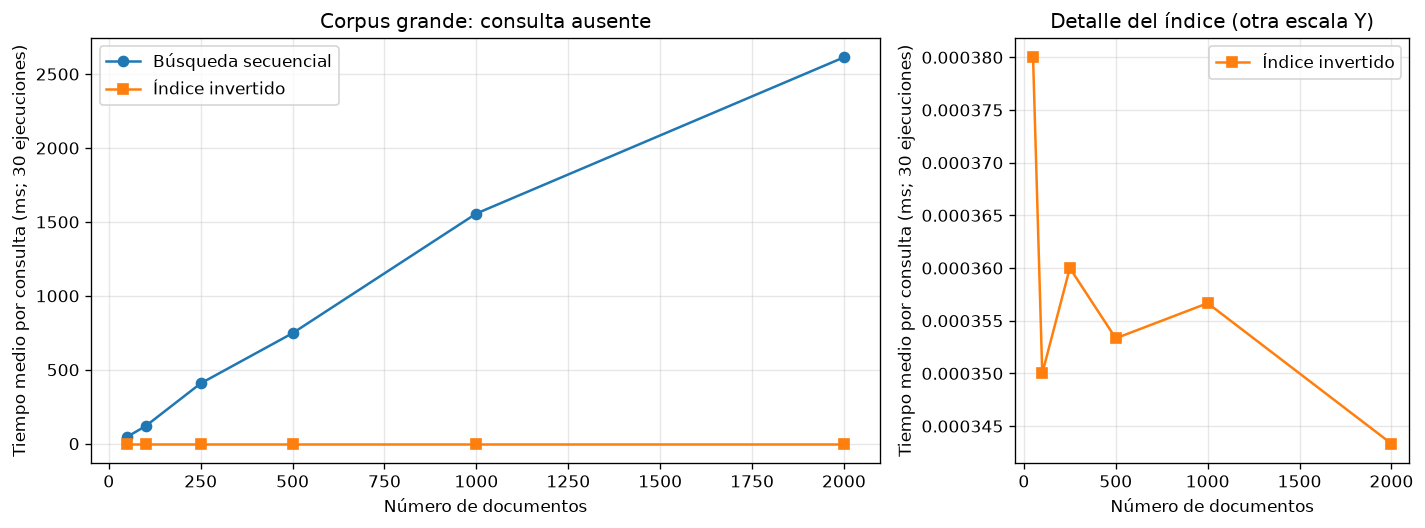

**Resultado del ejercicio 8.** Se midieron **6/6 tamaños** con la consulta fija `xyzterminoinexistente987654321` (DF = 0). Entre **50** y **2000** documentos, T paso de **2,415,311** a **139,798,472** y la media secuencial de **46.749527** a **2613.371387 ms**. Estos valores corresponden a esta ejecucion; no demuestran por si solos la complejidad del algoritmo.

In [8]:
# EJERCICIO 8. Se mide la busqueda con seis tamaños del corpus.
COLUMNAS_ESCALA = ["n_documentos", "tokens_totales", "consulta", "df_consulta", "secuencial_ms",
                  "indice_ms", "construccion_indice_ms", "repeticiones", "identicos"]


def medir_escalabilidad(documentos, tamanos, consulta, max_rss_mib=MAX_RSS_MIB):
    tamanos = list(tamanos)
    if (len(tamanos) < 5 or tamanos != sorted(set(tamanos))
            or any(not isinstance(n, int) or n < 1 for n in tamanos)):
        raise ValueError("Se requieren al menos cinco tamaños enteros, positivos y crecientes.")
    if max(tamanos) > len(documentos):
        raise ValueError("No hay suficientes documentos para todos los tamaños solicitados.")
    preparado = normalizar_termino(consulta)
    ids_ordenados = list(documentos)
    # Se comprueba que la consulta no aparece antes de medir.
    if any(preparado in documentos[doc] for doc in ids_ordenados[:max(tamanos)]):
        raise ValueError("La consulta del peor caso existe en el corpus. Configure otra consulta fija.")
    medidas = []
    for n in tamanos:
        print(f"Ejercicio 8: {n} documentos, consulta ausente, 30 mediciones por método...", flush=True)
        if memoria_rss_mib() >= max_rss_mib:
            print("Experimento parcial: se alcanzó el límite RSS antes del tamaño", n)
            break
        subcorpus = {doc: documentos[doc] for doc in ids_ordenados[:n]}
        inicio = time.perf_counter_ns()
        subindice = construir_indice(subcorpus)
        construccion_ms = (time.perf_counter_ns() - inicio) / 1e6
        # Se comparan las respuestas fuera del cronometro.
        res_seq = buscar_secuencial(subcorpus, preparado, normalizado=True)
        res_idx = buscar_indice(subindice, preparado, normalizado=True)
        assert res_seq == res_idx == []
        seq_ms = medir_tiempo_medio(buscar_secuencial, subcorpus, preparado, normalizado=True)
        idx_ms = medir_tiempo_medio(buscar_indice, subindice, preparado, normalizado=True)
        medidas.append({"n_documentos": n, "tokens_totales": sum(map(len, subcorpus.values())),
                        "consulta": preparado, "df_consulta": len(res_seq),
                        "secuencial_ms": seq_ms, "indice_ms": idx_ms,
                        "construccion_indice_ms": construccion_ms,
                        "repeticiones": REPETICIONES, "identicos": True})
        del subcorpus, subindice
        gc.collect()
    return pd.DataFrame(medidas, columns=COLUMNAS_ESCALA)


def graficar_escalabilidad(datos, contexto="Corpus grande"):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [2, 1]})
    ax, detalle = axes
    for columna, etiqueta, marca in [("secuencial_ms", "Búsqueda secuencial", "o"),
                                     ("indice_ms", "Índice invertido", "s")]:
        ax.plot(datos.n_documentos, datos[columna], marker=marca, label=etiqueta)
    detalle.plot(datos.n_documentos, datos.indice_ms, "s-", color="tab:orange", label="Índice invertido")
    ax.set_title(f"{contexto}: consulta ausente")
    detalle.set_title("Detalle del índice (otra escala Y)")
    for eje in axes:
        eje.set_xlabel("Número de documentos")
        eje.set_ylabel("Tiempo medio por consulta (ms; 30 ejecuciones)")
        eje.grid(alpha=0.3)
        eje.legend()
    fig.tight_layout()
    return fig


datos_escala = pd.DataFrame(columns=COLUMNAS_ESCALA)
if len(corpus_B) >= max(TAMANOS_OBJETIVO):
    datos_escala = medir_escalabilidad(corpus_B, TAMANOS_OBJETIVO, CONSULTA_ESCALABILIDAD)
    display(datos_escala)
    if not datos_escala.empty:
        fig = graficar_escalabilidad(datos_escala)
        plt.show()
        plt.close(fig)
        primero, ultimo = datos_escala.iloc[0], datos_escala.iloc[-1]
        display(Markdown(f"**Resultado del ejercicio 8.** Se midieron "
                         f"**{len(datos_escala)}/{len(TAMANOS_OBJETIVO)} tamaños** con la consulta fija "
                         f"`{CONSULTA_ESCALABILIDAD}` (DF = 0). Entre "
                         f"**{int(primero.n_documentos)}** y **{int(ultimo.n_documentos)}** documentos, "
                         f"T paso de **{int(primero.tokens_totales):,}** a **{int(ultimo.tokens_totales):,}** "
                         f"y la media secuencial de **{primero.secuencial_ms:.6f}** a "
                         f"**{ultimo.secuencial_ms:.6f} ms**. Estos valores corresponden a esta ejecucion; "
                         "no demuestran por si solos la complejidad del algoritmo."))
else:
    display(Markdown(f"**Ejercicio 8 pendiente:** hay **{len(corpus_B)} documentos grandes cargados** "
                     f"y hacen falta **{max(TAMANOS_OBJETIVO)}** para medir {TAMANOS_OBJETIVO}. "
                     "No se generan graficas experimentales sin esas mediciones."))
datos_escala.to_csv(DIRECTORIO_RESULTADOS / "escalabilidad_B.csv", index=False, encoding="utf-8-sig")



**Escalabilidad.** Se usa la misma consulta ausente en todos los tamaños. Su ausencia se comprueba antes de medir y obliga a recorrer todos los tokens con la busqueda secuencial. Tambien se registra T, porque los libros tienen longitudes distintas. La construccion del indice se mide aparte.

**9. Estimación de una función de tiempo**

Utilizando los resultados experimentales, determine una función:

$t=f(n)$

para cada método de recuperación.

Como primera aproximación, utilice un ajuste lineal por mínimos cuadrados:

$t(n)=an+b$

Estime los parámetros $a$ y $b$, reporte el coeficiente de determinación $R^2$ y represente las funciones ajustadas junto a los datos experimentales.

Explique si el modelo lineal representa adecuadamente las mediciones y cómo se relaciona con la complejidad computacional de cada algoritmo.

,Metodo,columna,a_ms_por_documento,b_ms,R2
0,Secuencial,secuencial_ms,1.327741e+00,52.130384,0.989675
1,Índice invertido,indice_ms,-1.045400e-08,0.000364,0.387413


,n_documentos,secuencial_ms,indice_ms,prediccion_secuencial_ms,residuo_secuencial_ms,prediccion_indice_ms,residuo_indice_ms
0,50,46.749527,0.000380,118.517442,-71.767915,0.000363,1.650538e-05
1,100,118.687457,0.000350,184.904499,-66.217043,0.000363,-1.297192e-05
2,250,407.826553,0.000360,384.065672,23.760881,0.000361,-1.403823e-06
3,500,747.426750,0.000353,716.000960,31.425790,0.000359,-5.456989e-06
4,1000,1556.911127,0.000357,1379.871537,177.039590,0.000354,3.103345e-06
5,2000,2613.371387,0.000343,2707.612689,-94.241302,0.000343,2.240143e-07


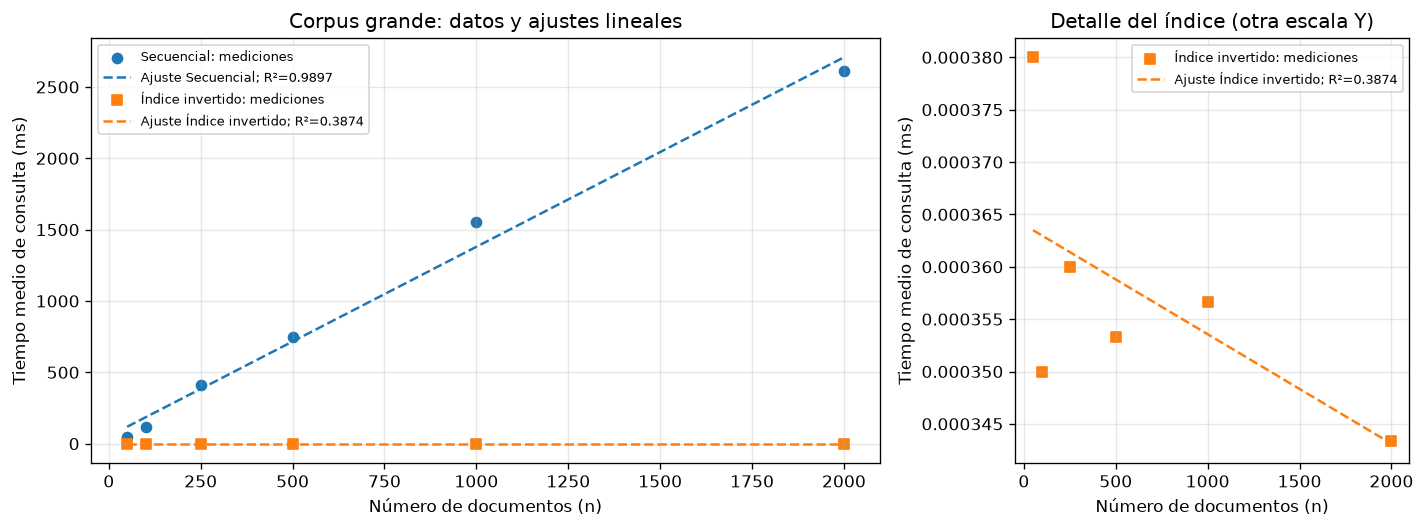

**Resultado del ejercicio 9 (Secuencial).** t(n) = **(1.32774115)n + (52.1303842) ms**, **R² = 0.98968**: la recta se ajusta bien a los tiempos medidos, en **6 tamaños**. El ajuste y las predicciones usan la tabla del ejercicio 8. Los coeficientes negativos pueden aparecer por ruido de medicion. La recta no debe usarse para predecir tiempos fuera de los tamaños medidos.

**Resultado del ejercicio 9 (Índice invertido).** t(n) = **(-1.04540024e-08)n + (0.000364017324) ms**, **R² = 0.38741**: la recta explica poco la variacion de los tiempos, en **6 tamaños**. El ajuste y las predicciones usan la tabla del ejercicio 8. Los coeficientes negativos pueden aparecer por ruido de medicion. La recta no debe usarse para predecir tiempos fuera de los tamaños medidos.

Pruebas unitarias de regresión: recta conocida y serie constante correctas.


In [ ]:
# EJERCICIO 9. Se ajusta una recta con los tiempos del ejercicio 8.
def ajustar_recta(n, tiempos_ms):
    x = np.asarray(n, dtype=float)
    y = np.asarray(tiempos_ms, dtype=float)
    if (x.ndim != 1 or y.ndim != 1 or len(x) != len(y) or len(x) < 2
            or len(np.unique(x)) < 2 or not np.isfinite(x).all() or not np.isfinite(y).all()):
        raise ValueError("Se necesitan vectores finitos de igual longitud y dos tamaños distintos.")
    a, b = np.polyfit(x, y, deg=1)
    predicciones = a * x + b
    suma_residuos = float(np.sum((y - predicciones)**2))
    suma_total = float(np.sum((y - np.mean(y))**2))
    r2 = 1 - suma_residuos / suma_total if suma_total > 0 else float("nan")
    return float(a), float(b), r2, predicciones


def calcular_modelos(datos):
    if len(datos) < 5:
        raise ValueError("El ejercicio exige al menos cinco mediciones reales.")
    resultados, predicciones = [], datos[["n_documentos", "secuencial_ms", "indice_ms"]].copy()
    for nombre, columna in [("Secuencial", "secuencial_ms"), ("Índice invertido", "indice_ms")]:
        a, b, r2, estimados = ajustar_recta(datos.n_documentos, datos[columna])
        resultados.append({"Metodo": nombre, "columna": columna, "a_ms_por_documento": a,
                           "b_ms": b, "R2": r2})
        predicciones[f"prediccion_{columna}"] = estimados
        predicciones[f"residuo_{columna}"] = datos[columna].to_numpy() - estimados
    return pd.DataFrame(resultados), predicciones


def graficar_ajustes(datos, coeficientes, predicciones, contexto="Corpus grande"):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [2, 1]})
    ax, detalle = axes
    for _, fila in coeficientes.iterrows():
        columna = fila.columna
        color = "tab:blue" if columna == "secuencial_ms" else "tab:orange"
        marca = "o" if columna == "secuencial_ms" else "s"
        for eje in ([ax, detalle] if columna == "indice_ms" else [ax]):
            eje.scatter(datos.n_documentos, datos[columna], marker=marca, color=color,
                        label=f"{fila.Metodo}: mediciones")
            eje.plot(predicciones.n_documentos, predicciones[f"prediccion_{columna}"],
                     "--", color=color, label=f"Ajuste {fila.Metodo}; R²={fila.R2:.4f}")
    ax.set_title(f"{contexto}: datos y ajustes lineales")
    detalle.set_title("Detalle del índice (otra escala Y)")
    for eje in axes:
        eje.set_xlabel("Número de documentos (n)")
        eje.set_ylabel("Tiempo medio de consulta (ms)")
        eje.grid(alpha=0.3)
        eje.legend(fontsize=8)
    fig.tight_layout()
    return fig


resultados_ajuste = pd.DataFrame(columns=["Metodo", "columna", "a_ms_por_documento", "b_ms", "R2"])
predicciones_ajuste = pd.DataFrame(columns=["n_documentos", "secuencial_ms", "indice_ms",
                                          "prediccion_secuencial_ms", "prediccion_indice_ms"])
if len(datos_escala) >= 5:
    resultados_ajuste, predicciones_ajuste = calcular_modelos(datos_escala)
    display(resultados_ajuste)
    display(predicciones_ajuste)
    fig = graficar_ajustes(datos_escala, resultados_ajuste, predicciones_ajuste)
    plt.show()
    plt.close(fig)
    for _, fila in resultados_ajuste.iterrows():
        if not np.isfinite(fila.R2):
            comentario = "R² indefinido: los tiempos observados son constantes"
        elif fila.R2 >= 0.90:
            comentario = "la recta se ajusta bien a los tiempos medidos"
        elif fila.R2 >= 0.70:
            comentario = "la recta explica parte de la variacion de los tiempos"
        else:
            comentario = "la recta explica poco la variacion de los tiempos"
        display(Markdown(f"**Resultado del ejercicio 9 ({fila.Metodo}).** "
                         f"t(n) = **({fila.a_ms_por_documento:.9g})n + ({fila.b_ms:.9g}) ms**, "
                         f"**R² = {fila.R2:.5f}**: {comentario}, "
                         f"en **{len(datos_escala)} tamaños**. "
                         "El ajuste y las predicciones usan la tabla del ejercicio 8. "
                         "Los coeficientes negativos pueden aparecer por ruido de medicion. "
                         "La recta no debe usarse para predecir tiempos fuera de los tamaños medidos."))
else:
    display(Markdown("**Ejercicio 9 pendiente:** faltan al menos cinco mediciones reales del ejercicio 8. "
                     "No se reportan coeficientes, R² ni rectas del corpus grande."))

# Se comprueba el ajuste con una recta conocida y una serie constante.
_a, _b, _r2, _y = ajustar_recta([1, 2, 3, 4, 5], [3, 5, 7, 9, 11])
assert np.isclose(_a, 2) and np.isclose(_b, 1) and np.isclose(_r2, 1)
assert np.isnan(ajustar_recta([1, 2, 3], [7, 7, 7])[2])
print("Pruebas unitarias de regresión: recta conocida y serie constante correctas.")
resultados_ajuste.to_csv(DIRECTORIO_RESULTADOS / "ajustes_B.csv", index=False, encoding="utf-8-sig")
predicciones_ajuste.to_csv(DIRECTORIO_RESULTADOS / "predicciones_B.csv", index=False, encoding="utf-8-sig")
if not comparacion_A.empty:
    comparacion_A.to_csv(DIRECTORIO_RESULTADOS / "comparacion_A.csv", index=False, encoding="utf-8-sig")
    df_corpus_A.to_csv(DIRECTORIO_RESULTADOS / "corpus_A.csv", index=False, encoding="utf-8-sig")



**Complejidad.** El recorrido secuencial tiene peor caso O(T), o O(nm) si cada documento tiene unos m tokens. Ordenar los k resultados agrega O(k log k); para una consulta ausente k = 0. Tener dos bucles no implica O(n²).

Construir el indice cuesta O(T + Σ df(t) log df(t)) esperado, porque se recorren los tokens y se ordenan los postings. Su memoria es O(|V| + Σ df(t)), aparte del corpus. Consultar una clave cuesta O(1) promedio y copiar sus postings cuesta O(df).

Las consultas booleanas crean conjuntos con costo O(df₁ + df₂), realizan la operacion y ordenan los k resultados en O(k log k). `NOT` usa el universo: O(n + df), mas la ordenacion.

**Ajuste lineal.** R² describe estas mediciones y no demuestra la complejidad. Los comentarios sobre un ajuste alto, moderado o bajo son descriptivos. Una consulta ausente al indice tiene un costo esperado constante; una pendiente pequeña puede reflejar ruido. Las predicciones y conclusiones se calculan desde la tabla actual.

### Reproduccion y entrega

Las tablas, conclusiones y graficas estan guardadas en el notebook. Se pueden ver en GitHub sin descargar los libros ni usar archivos auxiliares.

Para repetir los experimentos se necesita Python 3.12 o posterior y los paquetes `nltk numpy pandas matplotlib requests psutil ipykernel`. Las versiones usadas aparecen en el ejercicio 1.

La ruta del corpus se configura con `RUTA_ARCHIVO` o `RI_ARCHIVO`. La ruta predeterminada es `%LOCALAPPDATA%/GutenbergRI/txt-files.tar.zip`, fuera de OneDrive. Se reutiliza el archivo local y la descarga automatica esta desactivada. El origen es el [archivo oficial de Gutenberg](https://www.gutenberg.org/cache/epub/feeds/txt-files.tar.zip).

Con **Restart Kernel and Run All** se ejecutan las celdas en orden. Cada tiempo medio usa 30 llamadas. Las pruebas con cuatro documentos y la recta conocida son comprobaciones, no experimentos del corpus grande.

La entrega principal es `02_booleansearch.ipynb`. `.gitignore` excluye el corpus, los entornos y los resultados auxiliares. No se necesitan CSV, JSON, HTML ni carpetas adicionales para visualizar el trabajo.

La ultima celda se ejecuto en otro nucleo. Se omite su numero de ejecucion para no mezclar secuencias. Sus resultados guardados se conservan.